# Détection de fraude bancaire par réseau de neurones (PyTorch)

Ce notebook présente un projet complet de **classification binaire** : prédire si une transaction bancaire est **frauduleuse** (`is_fraud = 1`) ou **légitime** (`is_fraud = 0`) à partir de ses caractéristiques (montant, canal de paiement, appareil utilisé, score de risque du marchand, etc.).

## Plan

1. **Prétraitement** : encodage des variables catégorielles et normalisation Min-Max (entraînement et test).
2. **Expérimentations** : trois réseaux de neurones comparés (baseline sur 8 variables, réseau sur 42 variables, réseau plus profond), puis choix du modèle final.
3. **Prédictions** sur le jeu de test et export de `resultat.csv`.
4. **Bilan** : résultats, limites connues et pistes d'amélioration.

## Données

| Fichier | Rôle | Taille |
|---|---|---|
| `train.csv` | jeu d'entraînement étiqueté (colonne `is_fraud`) | 699 960 lignes × 26 colonnes |
| `test.csv` | jeu de test, sans étiquette | 299 984 lignes |

Les fraudes sont **rares** (environ 1,7 % des transactions de la validation). C'est la principale difficulté du problème : une *accuracy* élevée peut cacher un modèle qui ne détecte presque aucune fraude. On suivra donc surtout la **précision**, le **rappel**, le **F1-score** et l'**AUC**.

## Fichiers produits par le notebook

| Fichier | Contenu |
|---|---|
| `train_normalized.csv` | jeu d'entraînement encodé et normalisé (partie 1) |
| `data_test_normalized.csv` | jeu de test encodé et normalisé (partie 1) |
| `test_train.csv`, `test_test.csv` | fichiers intermédiaires de l'expérience 1 |
| `model_weights.pth` | poids du réseau retenu |
| `resultat.csv` | prédictions finales (`id`, probabilité de fraude) |

> **Dépendances** : `pandas`, `numpy`, `scikit-learn`, `torch`, `torchmetrics`, `tqdm`, `matplotlib`.
> Les imports sont faits au fil du notebook, au moment où ils servent.

---
# 1. Prétraitement des données

Les réseaux de neurones ne comprennent que des nombres, et apprennent mieux quand ces nombres sont à des échelles comparables. Il faut donc :

1. **encoder** les variables textuelles (catégories, booléens) en valeurs numériques ;
2. **normaliser** toutes les variables entre 0 et 1 ;
3. appliquer **exactement les mêmes transformations** au jeu de test, avec les paramètres appris sur l'entraînement.

## 1.1 Chargement et premières inspections

In [ ]:
# Bibliothèques de base : pandas pour les tableaux, torch pour la suite
import pandas as pd
import torch

In [ ]:
# Chargement du jeu d'entraînement brut
data = pd.read_csv("train.csv")

# Indices des transactions frauduleuses (utilisé uniquement pour l'exploration)
fraud = []
for i in range(data.shape[0]):
    if data["is_fraud"].iloc[i] == 1.0 :
        fraud.append(i)

# Aperçu des 30 premières transactions
data.head(30)

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0
5,5,10.74,0.12,4,18.05,51,53,1885.81,0,56.3,...,PIN,ATM,Android Phone,False,False,True,False,False,False,0.0
6,6,20.56,4.99,3,18.07,54,78,769.62,0,15.3,...,3D Secure,Online,POS Terminal,False,False,False,False,False,False,0.0
7,7,38.08,12.08,6,11.53,52,24,4566.46,0,39.5,...,PIN,Online,Android Phone,False,False,False,False,False,False,0.0
8,8,15.06,4.88,5,7.85,47,54,682.02,0,18.5,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
9,9,26.48,3.72,2,1.52,40,27,4973.30,0,9.3,...,Biometric,POS,Android Phone,False,True,False,False,False,False,0.0


In [ ]:
# Inspection d'une transaction précise (ligne d'indice 7035)
data.iloc[7035]

id                                           7035
amount_usd                                  23.42
hours_since_last_txn                        11.17
txn_count_last_24h                              3
distance_from_home_km                       12.75
card_age_months                                43
customer_age                                   75
account_balance_usd                       3106.35
cvv_retry_count                                 1
velocity_score                               17.9
time_of_day_hour                               22
day_of_week                                     4
merchant_risk_score                          43.7
prior_disputes                                  0
merchant_category                            Fuel
card_type                                    Visa
auth_method                     No Authentication
channel                               Contactless
device_type                                iPhone
is_foreign_transaction                       True


In [ ]:
# Colonnes de position 9 à 17 : scores comportementaux et variables catégorielles encore sous forme de texte
data.iloc[:,9:18]

,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel
0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS
1,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App
2,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online
3,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS
4,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online
...,...,...,...,...,...,...,...,...,...
699955,20.8,1,3,54.8,0,Travel,Mastercard,3D Secure,POS
699956,65.0,5,1,43.9,0,Restaurants,Mastercard,No Authentication,Online
699957,19.3,4,6,38.7,0,Online Retail,Mastercard,Biometric,Online
699958,31.0,12,3,32.3,0,Groceries,Mastercard,PIN,ATM


In [ ]:
# Valeurs distinctes d'une variable booléenne
import numpy as np
np.unique(data["is_new_merchant"].to_numpy())

array([False,  True])

## 1.2 Encodage des variables catégorielles

Trois stratégies, selon la nature de la variable :

| Type de variable | Colonnes | Encodage |
|---|---|---|
| Catégories **sans ordre** et nombreuses | `merchant_category` (12 modalités), `device_type` (8 modalités) | **One-hot** : une colonne 0/1 par modalité |
| Catégories à **peu de modalités** | `card_type`, `auth_method`, `channel` | **Encodage entier** (0, 1, 2, …) |
| **Booléens** | `is_foreign_transaction`, `is_new_merchant`, `used_vpn`, `ip_country_mismatch`, `billing_shipping_mismatch`, `is_ai_generated_scam_attempt` | Conversion en `0.0` / `1.0` |

> L'encodage entier introduit un ordre artificiel entre les modalités (par exemple `Visa` = 4 > `Amex` = 0). C'est un choix de simplicité ; le one-hot serait plus rigoureux mais ajouterait des colonnes.

In [ ]:
# 1) One-hot encoding de la catégorie du marchand (12 nouvelles colonnes 0/1)
data = pd.get_dummies(data,columns = ["merchant_category"] , prefix = "merchant_category" , dtype = "float32")

# 2) Encodage entier de card_type, auth_method et channel.
# Chaque encodage est suivi d'un dictionnaire de correspondance (`encodage_*`) qui documente le codage ;
# ces dictionnaires ne sont pas réutilisés ensuite.
data["card_type"] = data["card_type"].replace(['Amex', 'Discover', 'Mastercard', 'RuPay', 'Visa'] , [0,1,2,3,4]).astype(float)

encodage_card_type = {'Amex':0
                      , 'Discover':1
                      , 'Mastercard':2
                      , 'RuPay':3
                      , 'Visa':4}

data["auth_method"] = data["auth_method"].replace(['3D Secure', 'Biometric', 'No Authentication', 'OTP', 'PIN'] , [0,1,2,3,4]).astype(float)
encodage_auth_method = {'3D Secure':0, 'Biometric':1, 'No Authentication':2, 'OTP':3, 'PIN':4}

data["channel"] = data["channel"].replace(['ATM', 'Contactless', 'In-App', 'Online', 'POS'] , [0,1,2,3,4]).astype(float)
encodage_channel = {'ATM' : 0, 'Contactless' : 1, 'In-App' : 2, 'Online':3, 'POS':4}

# 3) Booléens ('True'/'False') convertis en 1.0 / 0.0
data["is_foreign_transaction"] = data["is_foreign_transaction"].replace(['True','False'] , [1,0]).astype(float)
encodage_is_foreign_transaction = {'True':1 , 'False':0}

data["is_new_merchant"] = data["is_new_merchant"].replace(['True','False'] , [1,0]).astype(float)
encodage_is_new_merchant = {'True':1 , 'False':0}

data["used_vpn"] = data["used_vpn"].replace(['True','False'] , [1,0]).astype(float)
encodage_used_vpn = {'True':1 , 'False':0}


# Même conversion pour les trois autres indicateurs booléens
for e in ["ip_country_mismatch",	"billing_shipping_mismatch",	"is_ai_generated_scam_attempt"] : 
    data[e] = data[e].replace(['True','False'] , [1,0]).astype(float)


# 4) One-hot encoding du type d'appareil (8 nouvelles colonnes 0/1)
data = data = pd.get_dummies(data,columns = ["device_type"] , prefix = "device_type" , dtype = "float32")

## 1.3 Vérifications après encodage

On contrôle que les colonnes sont bien numériques et que les dimensions sont cohérentes : **44 colonnes** = `id` + 42 variables explicatives + `is_fraud`.

In [ ]:
# Contrôle visuel : aperçu, colonnes 20 à 43 (indicateurs et colonnes one-hot) et dimensions finales
display(data.head())
display(data.iloc[:,20:44])
print(data.shape)

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,merchant_category_Travel,merchant_category_Utilities,device_type_ATM Machine,device_type_Android Phone,device_type_Mac,device_type_POS Terminal,device_type_Smart Watch,device_type_Tablet,device_type_Windows PC,device_type_iPhone
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud,merchant_category_Crypto Exchange,merchant_category_Electronics,merchant_category_Fuel,merchant_category_Gaming,merchant_category_Gift Cards,merchant_category_Groceries,...,merchant_category_Travel,merchant_category_Utilities,device_type_ATM Machine,device_type_Android Phone,device_type_Mac,device_type_POS Terminal,device_type_Smart Watch,device_type_Tablet,device_type_Windows PC,device_type_iPhone
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699955,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
699956,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
699957,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
699958,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


(699960, 44)


In [ ]:
# card_type est bien devenu numérique (valeurs de 0.0 à 4.0)
data["card_type"]

0         2.0
1         4.0
2         4.0
3         2.0
4         4.0
         ... 
699955    2.0
699956    2.0
699957    2.0
699958    2.0
699959    2.0
Name: card_type, Length: 699960, dtype: float64

In [ ]:
# Liste des colonnes après encodage : `is_fraud` se retrouve au milieu du tableau (position 23),
# d'où la réorganisation de l'étape suivante
data.columns

Index(['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'card_type', 'auth_method', 'channel',
       'is_foreign_transaction', 'is_new_merchant', 'used_vpn',
       'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt', 'is_fraud',
       'merchant_category_Crypto Exchange', 'merchant_category_Electronics',
       'merchant_category_Fuel', 'merchant_category_Gaming',
       'merchant_category_Gift Cards', 'merchant_category_Groceries',
       'merchant_category_Healthcare', 'merchant_category_Online Retail',
       'merchant_category_Restaurants', 'merchant_category_Streaming',
       'merchant_category_Travel', 'merchant_category_Utilities',
       'device_type_ATM Machine', 'device_type_Android Phone',
       '

## 1.4 Réorganisation des colonnes

On place `id` en **première** colonne et `is_fraud` (la cible) en **dernière**. Cette convention est utilisée plus loin par la classe `Charger_data`, qui lit les variables avec `[1:-1]` (tout sauf `id` et `is_fraud`) et l'étiquette avec `[-1]`.

In [ ]:
# Réordonnancement des colonnes : id d'abord, is_fraud en dernier
data = data[['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'card_type', 'auth_method', 'channel',
       'is_foreign_transaction', 'is_new_merchant', 'used_vpn',
       'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt',
       'merchant_category_Crypto Exchange', 'merchant_category_Electronics',
       'merchant_category_Fuel', 'merchant_category_Gaming',
       'merchant_category_Gift Cards', 'merchant_category_Groceries',
       'merchant_category_Healthcare', 'merchant_category_Online Retail',
       'merchant_category_Restaurants', 'merchant_category_Streaming',
       'merchant_category_Travel', 'merchant_category_Utilities',
       'device_type_ATM Machine', 'device_type_Android Phone',
       'device_type_Mac', 'device_type_POS Terminal',
       'device_type_Smart Watch', 'device_type_Tablet',
       'device_type_Windows PC', 'device_type_iPhone','is_fraud']]

In [ ]:
# Vérification de l'ordre des colonnes
data.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,merchant_category_Utilities,device_type_ATM Machine,device_type_Android Phone,device_type_Mac,device_type_POS Terminal,device_type_Smart Watch,device_type_Tablet,device_type_Windows PC,device_type_iPhone,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


## 1.5 Normalisation Min-Max du jeu d'entraînement

Chaque colonne est ramenée dans l'intervalle [0, 1] :

$$x' = \frac{x - x_{min}}{x_{max} - x_{min}}$$

Sans cela, une variable en milliers (`account_balance_usd`) écraserait une variable de l'ordre de l'unité (`txn_count_last_24h`) pendant l'apprentissage.

> Le `MinMaxScaler` est appliqué à toutes les colonnes, `id` et `is_fraud` comprises. Pour `is_fraud` (déjà 0 ou 1), rien ne change ; l'`id` normalisé n'est de toute façon pas utilisé par le modèle.

In [ ]:
# Normalisation Min-Max de scikit-learn
from sklearn.preprocessing import MinMaxScaler

In [ ]:
# Le scaler apprend le min et le max de chaque colonne sur le jeu d'ENTRAÎNEMENT, puis les applique
scaler = MinMaxScaler()

data_normalized = scaler.fit_transform(data)

In [ ]:
# `fit_transform` renvoie un tableau NumPy : on reconstruit un DataFrame en restaurant les noms de colonnes
data_normalized = pd.DataFrame(data_normalized , columns = ['id','amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'card_type', 'auth_method', 'channel',
       'is_foreign_transaction', 'is_new_merchant', 'used_vpn',
       'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt',
       'merchant_category_Crypto Exchange', 'merchant_category_Electronics',
       'merchant_category_Fuel', 'merchant_category_Gaming',
       'merchant_category_Gift Cards', 'merchant_category_Groceries',
       'merchant_category_Healthcare', 'merchant_category_Online Retail',
       'merchant_category_Restaurants', 'merchant_category_Streaming',
       'merchant_category_Travel', 'merchant_category_Utilities',
       'device_type_ATM Machine', 'device_type_Android Phone',
       'device_type_Mac', 'device_type_POS Terminal',
       'device_type_Smart Watch', 'device_type_Tablet',
       'device_type_Windows PC', 'device_type_iPhone','is_fraud'])

In [ ]:
# Contrôle : toutes les valeurs sont désormais comprises entre 0 et 1


data_normalized.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,merchant_category_Utilities,device_type_ATM Machine,device_type_Android Phone,device_type_Mac,device_type_POS Terminal,device_type_Smart Watch,device_type_Tablet,device_type_Windows PC,device_type_iPhone,is_fraud
0,0.000000,0.008755,0.187801,0.090909,0.306922,0.479167,0.603175,0.012154,0.0,0.075446,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.000001,0.003468,0.029440,0.272727,0.225445,0.270833,0.158730,0.031861,0.0,0.458162,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.000003,0.000780,0.022898,0.363636,0.141032,0.520833,0.587302,0.009922,0.0,0.491084,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,0.000004,0.005303,0.098518,0.363636,0.149663,0.479167,0.476190,0.021672,0.0,0.283951,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.000006,0.095006,0.015201,0.363636,0.201795,0.250000,0.539683,0.032444,0.0,0.477366,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [ ]:
# Sauvegarde du jeu d'entraînement prêt à être utilisé par le réseau de neurones
data_normalized.to_csv("train_normalized.csv" , index = False)

## 1.6 Prétraitement du jeu de test

Le jeu de test subit **les mêmes transformations**, avec deux précautions :

- on utilise `scaler.transform` (et **non** `fit_transform`) pour réutiliser les min/max appris sur l'entraînement. Recalculer ces valeurs sur le test ferait fuiter de l'information du test vers l'entraînement et rendrait les échelles incohérentes ;
- le test n'a pas de colonne `is_fraud`, alors que le scaler en attend une. On ajoute donc une colonne **factice** (copiée du train, sans signification pour le test) uniquement pour respecter la forme attendue, puis on la supprime juste après.

On suppose que le test contient les mêmes modalités catégorielles que l'entraînement, ce qui garantit les mêmes colonnes one-hot.

In [ ]:
# Chargement du jeu de test brut (les `id` continuent après ceux du train : 699960, 699961, …)
data_test = pd.read_csv("test.csv")


data_test.head(30)

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
0,699960,28.21,4.52,4,17.87,37,45,1483.49,0,15.4,...,Visa,OTP,Online,iPhone,False,False,False,False,False,False
1,699961,644.90,5.48,1,6.68,52,28,2183.64,0,11.2,...,RuPay,PIN,Contactless,Android Phone,False,False,False,False,False,False
2,699962,20.53,12.20,3,15.39,44,75,1208.59,0,20.8,...,Visa,No Authentication,Online,iPhone,False,False,False,False,False,False
3,699963,10.83,6.90,2,44.34,50,54,1790.85,0,9.2,...,Mastercard,PIN,Contactless,Mac,False,False,False,False,False,False
4,699964,19.00,0.63,3,25.22,50,66,1676.18,0,20.0,...,Mastercard,PIN,In-App,Android Phone,False,False,False,False,False,False
5,699965,46.30,0.97,1,0.90,44,20,2369.53,0,13.5,...,Mastercard,Biometric,POS,iPhone,False,False,False,False,False,False
6,699966,81.33,1.91,3,20.91,47,43,2247.89,0,19.4,...,Visa,3D Secure,POS,iPhone,False,False,False,False,False,False
7,699967,35.68,7.10,2,15.81,47,36,511.73,0,11.2,...,Mastercard,3D Secure,Online,Android Phone,False,False,False,False,False,False
8,699968,35.87,1.36,1,6.65,44,70,706.67,0,23.3,...,RuPay,PIN,Online,Android Phone,False,True,False,False,False,False
9,699969,11.07,4.36,3,5.33,54,19,533.30,0,21.3,...,Visa,3D Secure,Online,Android Phone,False,False,False,False,False,False


In [ ]:
# Mêmes encodages que pour le jeu d'entraînement (mêmes codes entiers, mêmes colonnes one-hot)
data_test = pd.get_dummies(data_test,columns = ["merchant_category"] , prefix = "merchant_category" , dtype = "float32")

data_test["card_type"] = data_test["card_type"].replace(['Amex', 'Discover', 'Mastercard', 'RuPay', 'Visa'] , [0,1,2,3,4]).astype(float)

encodage_card_type = {'Amex':0
                      , 'Discover':1
                      , 'Mastercard':2
                      , 'RuPay':3
                      , 'Visa':4}

data_test["auth_method"] = data_test["auth_method"].replace(['3D Secure', 'Biometric', 'No Authentication', 'OTP', 'PIN'] , [0,1,2,3,4]).astype(float)
encodage_auth_method = {'3D Secure':0, 'Biometric':1, 'No Authentication':2, 'OTP':3, 'PIN':4}

data_test["channel"] = data_test["channel"].replace(['ATM', 'Contactless', 'In-App', 'Online', 'POS'] , [0,1,2,3,4]).astype(float)
encodage_channel = {'ATM' : 0, 'Contactless' : 1, 'In-App' : 2, 'Online':3, 'POS':4}

data_test["is_foreign_transaction"] = data_test["is_foreign_transaction"].replace(['True','False'] , [1,0]).astype(float)
encodage_is_foreign_transaction = {'True':1 , 'False':0}

data_test["is_new_merchant"] = data_test["is_new_merchant"].replace(['True','False'] , [1,0]).astype(float)
encodage_is_new_merchant = {'True':1 , 'False':0}

data_test["used_vpn"] = data_test["used_vpn"].replace(['True','False'] , [1,0]).astype(float)
encodage_used_vpn = {'True':1 , 'False':0}


for e in ["ip_country_mismatch",	"billing_shipping_mismatch",	"is_ai_generated_scam_attempt"] : 
    data_test[e] = data_test[e].replace(['True','False'] , [1,0]).astype(float)


# One-hot encoding du type d'appareil
data_test = data_test = pd.get_dummies(data_test,columns = ["device_type"] , prefix = "device_type" , dtype = "float32")

In [ ]:
# Colonne `is_fraud` factice : elle sert uniquement à avoir les 44 colonnes attendues par le scaler
data_test["is_fraud"] = data_normalized["is_fraud"]
data_test.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,merchant_category_Utilities,device_type_ATM Machine,device_type_Android Phone,device_type_Mac,device_type_POS Terminal,device_type_Smart Watch,device_type_Tablet,device_type_Windows PC,device_type_iPhone,is_fraud
0,699960,28.21,4.52,4,17.87,37,45,1483.49,0,15.4,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,699961,644.90,5.48,1,6.68,52,28,2183.64,0,11.2,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,699962,20.53,12.20,3,15.39,44,75,1208.59,0,20.8,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,699963,10.83,6.90,2,44.34,50,54,1790.85,0,9.2,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,699964,19.00,0.63,3,25.22,50,66,1676.18,0,20.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
# `transform` : on réutilise les min/max du jeu d'entraînement (pas de nouvel apprentissage)
data_test_normalized = scaler.transform(data_test)

data_test_normalized = pd.DataFrame(data_test_normalized , columns = ['id','amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'card_type', 'auth_method', 'channel',
       'is_foreign_transaction', 'is_new_merchant', 'used_vpn',
       'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt',
       'merchant_category_Crypto Exchange', 'merchant_category_Electronics',
       'merchant_category_Fuel', 'merchant_category_Gaming',
       'merchant_category_Gift Cards', 'merchant_category_Groceries',
       'merchant_category_Healthcare', 'merchant_category_Online Retail',
       'merchant_category_Restaurants', 'merchant_category_Streaming',
       'merchant_category_Travel', 'merchant_category_Utilities',
       'device_type_ATM Machine', 'device_type_Android Phone',
       'device_type_Mac', 'device_type_POS Terminal',
       'device_type_Smart Watch', 'device_type_Tablet',
       'device_type_Windows PC', 'device_type_iPhone','is_fraud'])

In [ ]:
# On restaure l'`id` d'origine (non normalisé) pour identifier les transactions dans le fichier final,
# et on retire la colonne `is_fraud` factice
data_test_normalized["id"] = data_test["id"]

data_test_normalized = data_test_normalized[['id','amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'card_type', 'auth_method', 'channel',
       'is_foreign_transaction', 'is_new_merchant', 'used_vpn',
       'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt',
       'merchant_category_Crypto Exchange', 'merchant_category_Electronics',
       'merchant_category_Fuel', 'merchant_category_Gaming',
       'merchant_category_Gift Cards', 'merchant_category_Groceries',
       'merchant_category_Healthcare', 'merchant_category_Online Retail',
       'merchant_category_Restaurants', 'merchant_category_Streaming',
       'merchant_category_Travel', 'merchant_category_Utilities',
       'device_type_ATM Machine', 'device_type_Android Phone',
       'device_type_Mac', 'device_type_POS Terminal',
       'device_type_Smart Watch', 'device_type_Tablet',
       'device_type_Windows PC', 'device_type_iPhone']]

In [ ]:
# Contrôle du jeu de test normalisé
data_test_normalized.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,merchant_category_Travel,merchant_category_Utilities,device_type_ATM Machine,device_type_Android Phone,device_type_Mac,device_type_POS Terminal,device_type_Smart Watch,device_type_Tablet,device_type_Windows PC,device_type_iPhone
0,699960,0.003960,0.086781,0.363636,0.308476,0.250000,0.428571,0.014303,0.0,0.211248,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,699961,0.093703,0.105253,0.090909,0.115312,0.562500,0.158730,0.021330,0.0,0.153635,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,699962,0.002842,0.234558,0.272727,0.265665,0.395833,0.904762,0.011545,0.0,0.285322,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,699963,0.001431,0.132576,0.181818,0.765407,0.520833,0.571429,0.017388,0.0,0.126200,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,699964,0.002619,0.011930,0.272727,0.435353,0.520833,0.761905,0.016237,0.0,0.274348,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
# Sauvegarde du jeu de test prêt pour la prédiction
data_test_normalized.to_csv("data_test_normalized.csv" , index = False)

---
# 2. Expérimentations avec un réseau de neurones

En pratique, on commence normalement par un modèle de machine learning classique. Ici, vu la grande quantité de données (près de 700 000 lignes), on teste **directement un réseau de neurones** pour évaluer ses performances.

Trois expériences sont menées :

| # | Expérience | Entrées | Objectif |
|---|---|---|---|
| 1 | Baseline | 8 variables numériques | Avoir un point de comparaison |
| 2 | Réseau complet | 42 variables (après encodage) | Mesurer l'apport des variables catégorielles |
| 3 | Réseau plus profond | 42 variables | Tester une couche cachée supplémentaire |

**Protocole** : 80 % des données pour l'entraînement, 20 % pour la validation (séparation aléatoire, graine fixée à 42). Seuil de décision : 0,5.

---
## Expérience 1 : baseline sur 8 variables numériques

On commence avec les seules variables numériques de base : `amount_usd`, `hours_since_last_txn`, `txn_count_last_24h`, `distance_from_home_km`, `card_age_months`, `customer_age`, `account_balance_usd` et `cvv_retry_count`.

### Mini-prétraitement de l'expérience 1

In [ ]:
# Imports pour l'expérience 1
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# Rechargement du jeu brut ; `shape` donne (nombre de lignes, nombre de colonnes)
dataset = pd.read_csv("train.csv")
dataset.shape

(699960, 26)

In [ ]:
dataset.head()


# Colonnes retenues : 'id', les 8 variables numériques et la cible 'is_fraud'
columns = ['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count',"is_fraud"]
dataset = dataset[columns]

In [ ]:
# Contrôle de la sélection
dataset.columns

dataset.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,0.0


In [ ]:
from sklearn.preprocessing import MinMaxScaler
# Normalisation Min-Max de 'id' + 8 variables (toutes les colonnes sauf la cible)
features_columns = columns[:-1]
scaler = MinMaxScaler()
numpy_features = dataset[features_columns].to_numpy()
dataset[features_columns] = scaler.fit_transform(numpy_features)

df = dataset

# Sauvegarde du jeu d'entraînement normalisé (utilisé par cette expérience)
df.to_csv("test_train.csv", index=False)

# Bloc de prototypage : train.csv est relu et transformé avec le même scaler.
# `test_test.csv` est écrit mais n'est pas utilisé ensuite (le vrai jeu de test est traité en partie 1)
test = pd.read_csv("train.csv")
numpy_features = test[columns[:-1]].to_numpy()
dataset[columns[:-1]] = scaler.transform(numpy_features)
test.to_csv("test_test.csv",index = False)

dataset.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,is_fraud
0,0.000000,0.008755,0.187801,0.090909,0.306922,0.479167,0.603175,0.012154,0.0,0.0
1,0.000001,0.003468,0.029440,0.272727,0.225445,0.270833,0.158730,0.031861,0.0,0.0
2,0.000003,0.000780,0.022898,0.363636,0.141032,0.520833,0.587302,0.009922,0.0,0.0
3,0.000004,0.005303,0.098518,0.363636,0.149663,0.479167,0.476190,0.021672,0.0,0.0
4,0.000006,0.095006,0.015201,0.363636,0.201795,0.250000,0.539683,0.032444,0.0,0.0


### Chargement des données avec un `Dataset` PyTorch

La classe `Charger_data` lit un CSV et renvoie, pour chaque ligne, le couple *(variables, étiquette)* : les variables sont toutes les colonnes sauf la première (`id`) et la dernière (`is_fraud`), l'étiquette est la dernière colonne.

Les `DataLoader` découpent ensuite les données en **mini-batchs** : 100 transactions par batch (mélangées) pour l'entraînement, 1000 pour la validation.

In [ ]:
# Dataset PyTorch + séparation entraînement / validation + DataLoaders
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader


# Dataset : lit le CSV et renvoie (variables, étiquette) pour chaque ligne
class Charger_data(Dataset):
    def __init__(self, csv_path):
        super().__init__()
        self.data = pd.read_csv(csv_path).to_numpy(dtype = "float32")  # tout en float32, le type attendu par PyTorch

    def __len__(self):
        return self.data.shape[0]

    def __getitem__(self, idx):
        features = self.data[idx, 1:-1]  # toutes les colonnes sauf 'id' (première) et 'is_fraud' (dernière)
        label = self.data[idx, -1]  # la dernière colonne est la cible
        return features, label



from torch.utils.data import random_split, DataLoader

# Séparation 80 % entraînement / 20 % validation (graine fixée : résultat reproductible)
data = Charger_data("test_train.csv")

n_train = int(0.8 * len(data))
n_eval = len(data) - n_train
train_set, eval_set = random_split(
    data, [n_train, n_eval],
    generator=torch.Generator().manual_seed(42)  # reproductible
)

# DataLoaders : batchs de 100 (mélangés) pour l'entraînement, de 1000 pour la validation
train_loader = DataLoader(train_set, batch_size=100, shuffle=True, drop_last=True)
eval_loader = DataLoader(eval_set, batch_size=1000, shuffle=False)


# Vérification d'un batch : 100 lignes de 8 variables, avec leurs 100 étiquettes
X, y = next(iter(train_loader))
print(X.shape, y)   # (100, nb_features) et (100,)

torch.Size([100, 8]) tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])


In [ ]:
# Contrôle de l'étiquette : uniquement des 0 et des 1, aucune valeur manquante (NaN)
import numpy as np

data  = pd.read_csv("test_train.csv").to_numpy()
labels = data[:, -1]
print(np.unique(labels))
print(np.isnan(labels).sum())

[0. 1.]
0


### Architecture du réseau

Perceptron multicouche (MLP) à deux couches cachées :

```
entrée → Linear → BatchNorm → ELU → Linear → BatchNorm → ELU → Linear → Sigmoïde → probabilité de fraude
```

- **BatchNorm** : stabilise et accélère l'apprentissage ;
- **ELU** : fonction d'activation non linéaire, proche de ReLU mais plus douce pour les valeurs négatives ;
- **Sigmoïde** : ramène la sortie entre 0 et 1, interprétée comme une probabilité de fraude.

> La classe ci-dessous est la version à **42 entrées** (42 → 60 → 20 → 1), utilisée à partir de l'expérience 2. L'expérience 1 a été exécutée avec une version plus petite à 8 entrées (8 → 16 → 8 → 1), visible dans l'affichage du modèle après l'évaluation.

In [ ]:
# MLP : 42 entrées → 60 → 20 → 1 sortie (BatchNorm + ELU entre les couches, sigmoïde en sortie)
import torch.nn as nn
import torch.nn.init as init
class mon_model(nn.Module):
    def __init__(self):
        super().__init__()
        # Couche 1 : 42 variables d'entrée → 60 neurones
        self.fc1 = nn.Linear(42, 60)
        self.bn1 = nn.BatchNorm1d(60)
        # Couche 2 : 60 → 20 neurones
        self.fc2 = nn.Linear(60, 20)
        self.bn2 = nn.BatchNorm1d(20)
        # Couche de sortie : 1 neurone (probabilité de fraude)
        self.fc3 = nn.Linear(20, 1)
        
        
    def forward(self, x):
        # Bloc 1 : linéaire → BatchNorm → ELU
        x = self.fc1(x)
        x = self.bn1(x)
        x = nn.functional.elu(x)

        # Bloc 2 : même structure
        x = self.fc2(x)
        x = self.bn2(x)
        x = nn.functional.elu(x)

        # Sortie : probabilité comprise entre 0 et 1
        x = nn.functional.sigmoid(self.fc3(x))
        return x

### Entraînement

- **Optimiseur** : Adam, taux d'apprentissage 0,001.
- **Perte** : entropie croisée binaire (`BCELoss`), adaptée à une sortie en probabilité.
- **Durée** : 19 époques (une époque = un passage complet sur les données d'entraînement).

In [ ]:
from tqdm.auto import tqdm

# Initialisation : modèle, optimiseur Adam (lr = 0,001) et perte d'entropie croisée binaire
model = mon_model()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_function = torch.nn.BCELoss()

for epoch in range(1, 20):  # 19 époques
    model.train()
    total_loss = 0.0
    progress = tqdm(train_loader, desc=f"Epoch {epoch}/4" , colour = 'blue')  # le '/4' affiché est un reliquat d'un ancien essai à 4 époques

    # Pour chaque mini-batch : passe avant, calcul de la perte, rétropropagation, mise à jour des poids
    for features, labels in progress:
        optimizer.zero_grad()
        outputs = model(features)
        loss = loss_function(outputs, labels.view(-1, 1).float())
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        progress.set_postfix(loss=f"{loss.item():.4f}")

    print(f"Epoch {epoch} : loss moyenne = {total_loss / len(train_loader):.4f}")  # perte moyenne sur l'époque

Epoch 1/4: 100%|██████████| 5599/5599 [00:40<00:00, 138.41it/s, loss=0.1062]


Epoch 1 : loss moyenne = 0.0971


Epoch 2/4: 100%|██████████| 5599/5599 [00:40<00:00, 137.40it/s, loss=0.0920]


Epoch 2 : loss moyenne = 0.0713


Epoch 3/4: 100%|██████████| 5599/5599 [00:38<00:00, 144.79it/s, loss=0.1355]


Epoch 3 : loss moyenne = 0.0710


... (28 outputs left out)

Epoch 18/4: 100%|██████████| 5599/5599 [00:39<00:00, 142.70it/s, loss=0.1119]


Epoch 18 : loss moyenne = 0.0703


Epoch 19/4: 100%|██████████| 5599/5599 [00:38<00:00, 144.36it/s, loss=0.0759]

Epoch 19 : loss moyenne = 0.0703


### Évaluation de l'expérience 1

Rappel des métriques (avec *VP* = fraudes détectées, *FP* = fausses alertes, *FN* = fraudes manquées) :

- **Accuracy** : part de prédictions correctes. Trompeuse ici : prédire « jamais de fraude » donnerait déjà environ 98,3 %.
- **Précision** = VP / (VP + FP) : parmi les alertes, combien sont de vraies fraudes ?
- **Rappel** = VP / (VP + FN) : parmi les vraies fraudes, combien sont détectées ?
- **F1-score** : moyenne harmonique de la précision et du rappel.

In [ ]:
# Contrôle d'un batch de validation
X_eval, y_eval = next(iter(eval_loader))
print(X_eval.shape, y_eval)

torch.Size([2000, 8]) tensor([0., 0., 0.,  ..., 0., 0., 0.])


In [ ]:
# Évaluation sur le jeu de validation (seuil de décision : 0,5)
from torchmetrics import Accuracy, F1Score, Precision, Recall

metric = Accuracy(task="binary")
f1score = F1Score(task="binary")
precision = Precision(task="binary")
recall = Recall(task="binary")

# Mode évaluation : BatchNorm utilise les statistiques apprises (et non celles du batch)
model.eval()
# Prédictions par batch, sans calcul de gradient
with torch.no_grad():
    for X_eval, y_eval in eval_loader:
        outputs = model(X_eval).view(-1)
        preds = (outputs > 0.5).float()  # probabilité > 0,5 → fraude (1)
        target = y_eval.view(-1).float()

        metric.update(preds, target)
        f1score.update(preds, target)
        precision.update(preds, target)
        recall.update(preds, target)

# Agrégation des métriques sur tous les batchs de validation
acc = metric.compute()
f1 = f1score.compute()
pres = precision.compute()
rec = recall.compute()

print(f"accuracy  : {acc:.4f}")
print(f"precision : {pres:.4f}")
print(f"f1score   : {f1:.4f}")
print(f"recall    : {rec:.4f}")

# Retour en mode entraînement
model.train()

accuracy  : 0.9836
precision : 0.6882
f1score   : 0.0528
recall    : 0.0275


mon_model(
  (fc1): Linear(in_features=8, out_features=16, bias=True)
  (bn1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc2): Linear(in_features=16, out_features=8, bias=True)
  (bn2): BatchNorm1d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc3): Linear(in_features=8, out_features=1, bias=True)
)

In [ ]:
# Dernières prédictions binaires (0 / 1) du dernier batch de validation
preds

tensor([[0.],
        [0.],
        [0.],
        ...,
        [0.],
        [0.],
        [0.]])

### Résultats de l'expérience 1

| Accuracy | Précision | Rappel | F1 |
|---|---|---|---|
| 0,9836 | 0,6882 | 0,0275 | 0,0528 |

L'accuracy paraît excellente, mais le **rappel est de 2,7 %** : le réseau ne détecte presque aucune fraude et prédit « légitime » dans la quasi-totalité des cas. Avec seulement 8 variables numériques, l'information est insuffisante. On enrichit donc les données avec les variables catégorielles encodées en partie 1.

---
## Expérience 2 : réseau sur les 42 variables

On charge `train_normalized.csv` (produit en partie 1) et on refait le même protocole : séparation 80/20, mêmes réglages d'entraînement, 19 époques.

In [ ]:
# Chargement du jeu complet (42 variables) produit en partie 1
train = Charger_data("train_normalized.csv")

In [ ]:
# Nouvelle séparation 80 / 20 (même graine) et nouveaux DataLoaders
n_train = int(0.8 * len(train))
n_eval = len(train) - n_train
train_data, eval_data = random_split(
    train, [n_train, n_eval],
    generator=torch.Generator().manual_seed(42)  # reproductible
)

train_loader = DataLoader(train_data, batch_size=100, shuffle=True, drop_last=True)
eval_loader = DataLoader(eval_data, batch_size=1000, shuffle=False)

In [ ]:
# Vérification : les batchs contiennent maintenant 42 variables par transaction
X, y = next(iter(train_loader))
print(X.shape, y) 

torch.Size([100, 42]) tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])


In [ ]:
# Entraînement : mêmes réglages que l'expérience 1, mais avec 42 variables en entrée
from tqdm.auto import tqdm

# Initialisation : modèle, optimiseur Adam (lr = 0,001) et perte d'entropie croisée binaire
model = mon_model()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_function = torch.nn.BCELoss()

for epoch in range(1, 20):  # 19 époques
    model.train()
    total_loss = 0.0
    progress = tqdm(train_loader, desc=f"Epoch {epoch}/4" , colour = 'blue')  # le '/4' affiché est un reliquat d'un ancien essai à 4 époques

    # Pour chaque mini-batch : passe avant, calcul de la perte, rétropropagation, mise à jour des poids
    for features, labels in progress:
        optimizer.zero_grad()
        outputs = model(features)
        loss = loss_function(outputs, labels.view(-1, 1).float())
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        progress.set_postfix(loss=f"{loss.item():.4f}")

    print(f"Epoch {epoch} : loss moyenne = {total_loss / len(train_loader):.4f}")  # perte moyenne sur l'époque

Epoch 1/4: 100%|██████████| 5599/5599 [00:45<00:00, 124.20it/s, loss=0.0515]


Epoch 1 : loss moyenne = 0.0685


Epoch 2/4: 100%|██████████| 5599/5599 [00:45<00:00, 123.88it/s, loss=0.0225]


Epoch 2 : loss moyenne = 0.0520


Epoch 3/4: 100%|██████████| 5599/5599 [00:44<00:00, 124.98it/s, loss=0.0440]


Epoch 3 : loss moyenne = 0.0504


... (28 outputs left out)

Epoch 18/4: 100%|██████████| 5599/5599 [00:44<00:00, 125.55it/s, loss=0.0113]


Epoch 18 : loss moyenne = 0.0471


Epoch 19/4: 100%|██████████| 5599/5599 [00:44<00:00, 124.83it/s, loss=0.0088]

Epoch 19 : loss moyenne = 0.0471


In [ ]:
# Évaluation sur le jeu de validation
from torchmetrics import Accuracy, F1Score, Precision, Recall

metric = Accuracy(task="binary")
f1score = F1Score(task="binary")
precision = Precision(task="binary")
recall = Recall(task="binary")

# Mode évaluation : BatchNorm utilise les statistiques apprises (et non celles du batch)
model.eval()
# Prédictions par batch, sans calcul de gradient
with torch.no_grad():
    for X_eval, y_eval in eval_loader:
        outputs = model(X_eval).view(-1)
        preds = (outputs > 0.5).float()  # probabilité > 0,5 → fraude (1)
        target = y_eval.view(-1).float()

        metric.update(preds, target)
        f1score.update(preds, target)
        precision.update(preds, target)
        recall.update(preds, target)

# Agrégation des métriques sur tous les batchs de validation
acc = metric.compute()
f1 = f1score.compute()
pres = precision.compute()
rec = recall.compute()

print(f"accuracy  : {acc:.4f}")
print(f"precision : {pres:.4f}")
print(f"f1score   : {f1:.4f}")
print(f"recall    : {rec:.4f}")

# Retour en mode entraînement
model.train()

accuracy  : 0.9865
precision : 0.7592
f1score   : 0.4034
recall    : 0.2747


mon_model(
  (fc1): Linear(in_features=42, out_features=60, bias=True)
  (bn1): BatchNorm1d(60, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc2): Linear(in_features=60, out_features=20, bias=True)
  (bn2): BatchNorm1d(20, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc3): Linear(in_features=20, out_features=1, bias=True)
)

### Résultats de l'expérience 2

| Accuracy | Précision | Rappel | F1 |
|---|---|---|---|
| 0,9865 | 0,7592 | 0,2747 | 0,4034 |

La perte moyenne descend de 0,0685 à 0,0471 sur les 19 époques (contre 0,0703 en fin d'expérience 1). Le rappel est multiplié par dix et le F1 passe de 0,05 à 0,40 : **les variables catégorielles apportent beaucoup d'information**.

### Sauvegarde et rechargement du modèle

On sauvegarde les poids (`state_dict`), puis on vérifie qu'on retrouve exactement les mêmes performances après rechargement.

In [ ]:
# Sauvegarde des poids appris, pour pouvoir les recharger sans réentraîner
torch.save(model.state_dict(), "model_weights.pth")

In [ ]:
# Rechargement des poids dans une nouvelle instance du même modèle
model =mon_model()                    # même architecture qu'à l'entraînement
model.load_state_dict(torch.load("model_weights.pth"))
model.eval()                          # indispensable avant l'inférence (BatchNorm)

mon_model(
  (fc1): Linear(in_features=42, out_features=60, bias=True)
  (bn1): BatchNorm1d(60, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc2): Linear(in_features=60, out_features=20, bias=True)
  (bn2): BatchNorm1d(20, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc3): Linear(in_features=20, out_features=1, bias=True)
)

In [ ]:
# Vérification : mêmes métriques après rechargement des poids.
# NB : les objets `metric`, `f1score`, etc. ne sont pas réinitialisés, ils cumulent les passages successifs
# Évaluation du modèle rechargé
with torch.no_grad():
    for X_eval, y_eval in eval_loader:
        outputs = model(X_eval).view(-1)
        preds = (outputs > 0.5).float()
        target = y_eval.view(-1).float()

        metric.update(preds, target)
        f1score.update(preds, target)
        precision.update(preds, target)
        recall.update(preds, target)

acc = metric.compute()
f1 = f1score.compute()
pres = precision.compute()
rec = recall.compute()

print(f"accuracy  : {acc:.4f}")
print(f"precision : {pres:.4f}")
print(f"f1score   : {f1:.4f}")
print(f"recall    : {rec:.4f}")

model.train()

accuracy  : 0.9865
precision : 0.7592
f1score   : 0.4034
recall    : 0.2747


mon_model(
  (fc1): Linear(in_features=42, out_features=60, bias=True)
  (bn1): BatchNorm1d(60, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc2): Linear(in_features=60, out_features=20, bias=True)
  (bn2): BatchNorm1d(20, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc3): Linear(in_features=20, out_features=1, bias=True)
)

### Poursuite de l'entraînement et métriques complètes

Pour aller plus loin, on définit deux fonctions réutilisables :

- `train(model, dataset)` : entraîne un modèle (29 époques) ;
- `evaluate(model, eval_data)` : calcule les métriques, affiche la **matrice de confusion** et, dans sa deuxième version, l'**AUC** avec la **courbe ROC**.

L'**AUC** mesure la capacité du modèle à classer une fraude au-dessus d'une transaction légitime, **indépendamment du seuil** de décision : 0,5 correspond au hasard, 1 à un classement parfait. C'est une métrique mieux adaptée que l'accuracy aux classes déséquilibrées.

In [ ]:
# Fonction d'entraînement réutilisable.
# Elle s'appuie sur les variables globales `optimizer` et `loss_function` définies plus haut :
# l'optimiseur est lié aux paramètres de `model`.
def train(model , dataset):
    
    for epoch in range(1, 30):  # 29 époques
        model.train()
        total_loss = 0.0
        progress = tqdm(dataset, desc=f"Epoch {epoch}/5" , colour = 'blue')  # le '/5' affiché est un simple libellé
    
        for features, labels in progress:
            optimizer.zero_grad()
            outputs = model(features)
            loss = loss_function(outputs, labels.view(-1, 1).float())
            loss.backward()
            optimizer.step()
    
            total_loss += loss.item()
            progress.set_postfix(loss=f"{loss.item():.4f}")

In [ ]:
# Poursuite de l'entraînement de `model` pendant 29 époques supplémentaires
# (la sortie, très volumineuse, a été retirée du notebook)
train(model,train_loader)

In [ ]:
# Fonction d'évaluation complète : accuracy, précision, F1, rappel et matrice de confusion
from torchmetrics.classification import BinaryConfusionMatrix
import matplotlib.pyplot as plt

confmat = BinaryConfusionMatrix()

metric = Accuracy(task="binary")
f1score = F1Score(task="binary")
precision = Precision(task="binary")
recall = Recall(task="binary")


# Évaluation : les prédictions sont accumulées batch par batch dans les métriques
def evaluate(model, eval_data):
    
    with torch.no_grad():
        for X_eval, y_eval in eval_data:
            outputs = model(X_eval).view(-1)
            preds = (outputs > 0.5).float()
            target = y_eval.view(-1).float()
    
            metric.update(preds, target)
            f1score.update(preds, target)
            precision.update(preds, target)
            recall.update(preds, target)
            confmat.update(preds, target)
    
    acc = metric.compute()
    f1 = f1score.compute()
    pres = precision.compute()
    rec = recall.compute()
    cm = confmat.compute()
    
    print(f"accuracy  : {acc:.4f}")
    print(f"precision : {pres:.4f}")
    print(f"f1score   : {f1:.4f}")
    print(f"recall    : {rec:.4f}")
    print(cm)

    # Affichage graphique de la matrice de confusion
    confmat.plot(add_text=True)
    plt.show()
    
    model.train()

accuracy  : 0.9865
precision : 0.7620
f1score   : 0.4024
recall    : 0.2734
tensor([[274926,    398],
        [  3386,   1274]])


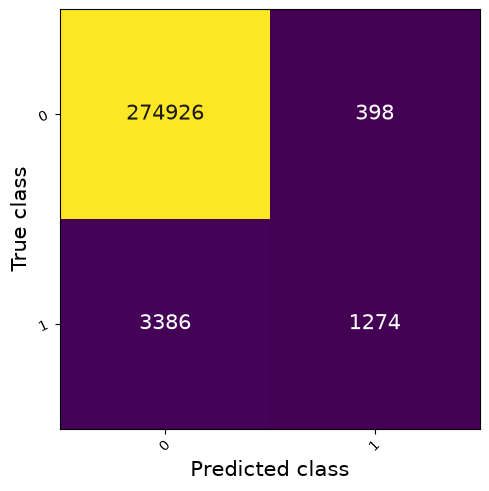

In [ ]:
# Évaluation avec matrice de confusion.
# NB : les métriques torchmetrics ne sont pas réinitialisées entre deux appels : les effectifs de la matrice
# cumulent les évaluations successives, seules les proportions (accuracy, précision, rappel, F1) sont interprétables.
evaluate(model , eval_loader)

In [ ]:
# Nouvelle version de `evaluate` : ajoute l'AUC et la courbe ROC.
# La ROC se calcule à partir des probabilités (`outputs`) et non des classes prédites (`preds`).
# NB : cette version lit la variable globale `eval_loader` (le paramètre `eval_data` n'est pas utilisé).
from torchmetrics.classification import BinaryAUROC, BinaryROC
import matplotlib.pyplot as plt

auroc = BinaryAUROC()
roc   = BinaryROC()

def evaluate(model, eval_data):
    
    with torch.no_grad():
        for X_eval, y_eval in eval_loader:
            outputs = model(X_eval).view(-1)
            preds = (outputs > 0.5).float()
            target = y_eval.view(-1).float()
    
            metric.update(preds, target)
            f1score.update(preds, target)
            precision.update(preds, target)
            recall.update(preds, target)
            confmat.update(preds, target)

            # ROC : on passe les scores (outputs), pas preds
            auroc.update(outputs, target.int())
            roc.update(outputs, target.int())
    
    acc = metric.compute()
    f1 = f1score.compute()
    pres = precision.compute()
    rec = recall.compute()
    cm = confmat.compute()
    auc = auroc.compute()
    
    print(f"accuracy  : {acc.item():.4f}")
    print(f"precision : {pres.item():.4f}")
    print(f"f1score   : {f1.item():.4f}")
    print(f"recall    : {rec.item():.4f}")
    print(f"roc auc   : {auc.item():.4f}")
    print(cm)
    plt.figure(figsize=(12,12))
    confmat.plot(add_text=True)
    roc.plot(score=True)   # courbe ROC avec l'AUC dans la légende
    plt.show()
    
    model.train()

accuracy  : 0.9865
precision : 0.7482
f1score   : 0.4095
recall    : 0.2819
roc auc   : 0.9355
tensor([[824646,   1326],
        [ 10039,   3941]])


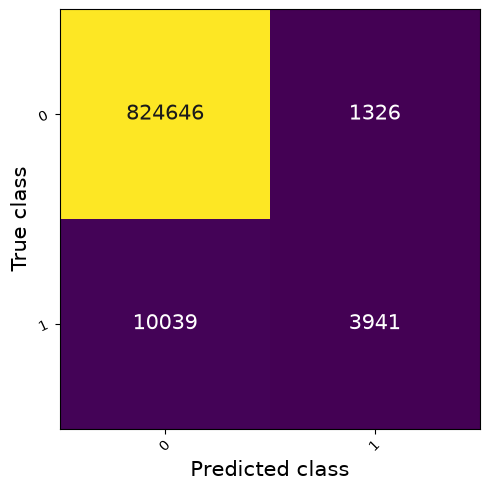

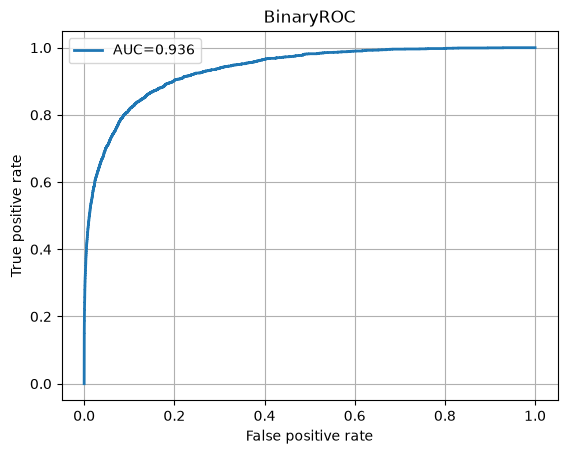

In [ ]:
# Évaluation complète : métriques, AUC, matrice de confusion et courbe ROC
evaluate(model,eval_loader)

---
## Expérience 3 : un réseau plus profond

On ajoute une couche cachée : 42 → 60 → 40 → 20 → 1. Plus de couches signifie plus de paramètres à apprendre ; on regarde si cela améliore les résultats.

In [ ]:
# Réseau plus profond : 42 → 60 → 40 → 20 → 1 (une couche cachée supplémentaire)
import torch.nn as nn

class mon_model2(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(42, 60)
        self.bn1 = nn.BatchNorm1d(60)
        self.fc2 = nn.Linear(60, 40)    # nouvelle couche
        self.bn2 = nn.BatchNorm1d(40)
        self.fc3 = nn.Linear(40, 20)
        self.bn3 = nn.BatchNorm1d(20)
        self.fc4 = nn.Linear(20, 1)

    def forward(self, x):
        x = nn.functional.elu(self.bn1(self.fc1(x)))
        x = nn.functional.elu(self.bn2(self.fc2(x)))
        x = nn.functional.elu(self.bn3(self.fc3(x)))
        x = torch.sigmoid(self.fc4(x))
        return x

In [ ]:
# Entraînement du réseau plus profond avec la même fonction `train`
# (sortie volumineuse retirée du notebook ; la perte affichée restait autour de 0,64)
model2 = mon_model2()

train(model2,train_loader)

### Résultat de l'expérience 3

Pendant l'entraînement de `model2`, la perte affichée reste **autour de 0,64** et ne diminue pas, alors que celle du réseau à deux couches cachées descendait sous 0,05. Le réseau plus profond n'a donc pas appris dans cet essai.

> **Point d'attention.** La fonction `train` utilise l'optimiseur **global**, créé pour `model` (`Adam(model.parameters())`). Les paramètres de `model2` n'y figurent pas : ils ne sont donc probablement pas mis à jour, ce qui expliquerait une perte figée proche de celle d'un réseau non entraîné. Cette comparaison est à refaire avec un optimiseur dédié à `model2` avant de conclure sur l'intérêt de la profondeur.

---
## Choix du modèle final

On **retient le réseau à deux couches cachées** (42 → 60 → 20 → 1), avec les poids sauvegardés après l'expérience 2 (`model_weights.pth`) : c'est le seul qui a clairement appris, et il est plus simple (moins de paramètres) que le réseau à trois couches cachées.

In [ ]:
# Chargement du modèle retenu avec les poids sauvegardés
model_choisit = mon_model()

model_choisit.load_state_dict(torch.load("model_weights.pth"))

<All keys matched successfully>

accuracy  : 0.9865
precision : 0.7543
f1score   : 0.4063
recall    : 0.2780
roc auc   : 0.9355
tensor([[1511961,    2321],
        [  18504,    7126]])


<Figure size 1200x1200 with 0 Axes>

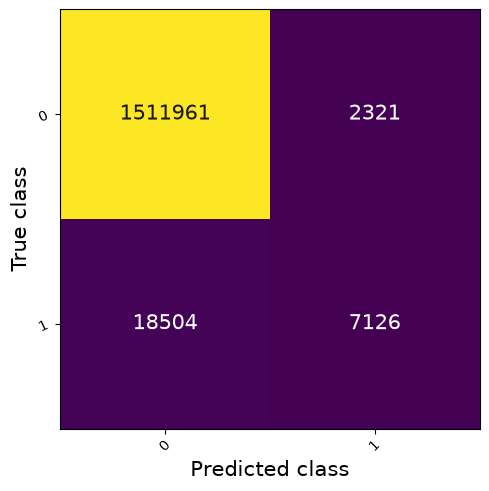

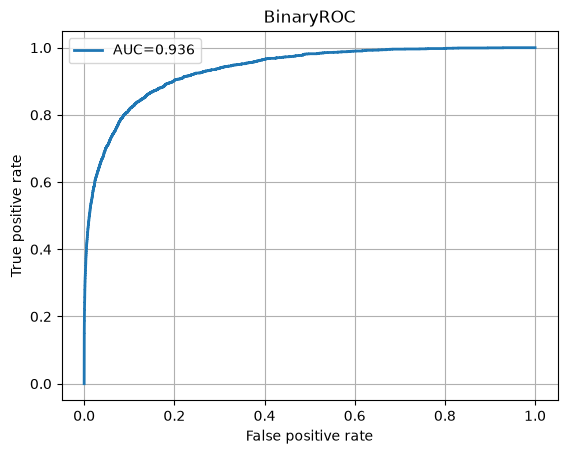

In [ ]:
# Évaluation finale du modèle retenu (mêmes remarques sur le cumul des effectifs de la matrice)
evaluate(model_choisit , eval_loader)

### Résultats du modèle retenu

| Accuracy | Précision | Rappel | F1 | AUC |
|---|---|---|---|---|
| 0,9865 | 0,7543 | 0,2780 | 0,4063 | 0,9355 |

- **AUC = 0,9355** : le modèle classe très bien les transactions par niveau de risque.
- **Précision ≈ 75 %** : trois alertes sur quatre sont de vraies fraudes.
- **Rappel ≈ 28 %** : seulement un peu plus d'une fraude sur quatre est détectée au seuil de 0,5. L'écart entre une bonne AUC et un rappel modeste indique que le **seuil de décision** n'est pas adapté au déséquilibre des classes (voir les pistes d'amélioration).

---
# 3. Prédictions sur le jeu de test

On charge le jeu de test normalisé (partie 1), on retire la colonne `id`, puis on calcule pour chaque transaction la **probabilité de fraude**. Le fichier `resultat.csv` associe chaque `id` à cette probabilité.

In [ ]:
# Chargement du jeu de test normalisé
data_test = pd.read_csv("data_test_normalized.csv")
# On retire la colonne 'id' : seules les 42 variables sont données au réseau
features_test = data_test.iloc[: , 1:]
features_test.head()

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,...,merchant_category_Travel,merchant_category_Utilities,device_type_ATM Machine,device_type_Android Phone,device_type_Mac,device_type_POS Terminal,device_type_Smart Watch,device_type_Tablet,device_type_Windows PC,device_type_iPhone
0,0.003960,0.086781,0.363636,0.308476,0.250000,0.428571,0.014303,0.0,0.211248,0.913043,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.093703,0.105253,0.090909,0.115312,0.562500,0.158730,0.021330,0.0,0.153635,0.391304,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.002842,0.234558,0.272727,0.265665,0.395833,0.904762,0.011545,0.0,0.285322,0.086957,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,0.001431,0.132576,0.181818,0.765407,0.520833,0.571429,0.017388,0.0,0.126200,0.347826,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0.002619,0.011930,0.272727,0.435353,0.520833,0.761905,0.016237,0.0,0.274348,0.608696,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
# Conversion en tenseur PyTorch (float32)
tensor_data_test = torch.tensor(features_test.to_numpy() , dtype = torch.float32)

In [ ]:
# Dimensions : (nombre de transactions, 42 variables)
tensor_data_test.shape

torch.Size([299984, 42])

In [ ]:
# Probabilité de fraude pour chaque transaction du jeu de test.
# NB : `model` désigne ici le réseau dont l'entraînement a été poursuivi ; pour utiliser strictement le modèle
# retenu à la section précédente, il faudrait passer par `model_choisit`.
prediction = model(tensor_data_test)

print(prediction.shape)

torch.Size([299984, 1])


In [ ]:
# Export : identifiant + probabilité de fraude (probabilité et non classe 0/1)
resultat = pd.DataFrame({"id" : data_test["id"].to_numpy().reshape(-1) , "is_fraud" : prediction.view(-1).detach().cpu().numpy() } )
resultat.to_csv("resultat.csv" , index = False)

---
# 4. Bilan

## Synthèse des expériences

| Expérience | Entrées | Accuracy | Précision | Rappel | F1 | AUC |
|---|---|---|---|---|---|---|
| 1. Baseline | 8 | 0,9836 | 0,6882 | 0,0275 | 0,0528 | n/d |
| 2. Réseau complet (19 époques) | 42 | 0,9865 | 0,7592 | 0,2747 | 0,4034 | n/d |
| **Modèle retenu** | **42** | **0,9865** | **0,7543** | **0,2780** | **0,4063** | **0,9355** |
| 3. Réseau plus profond | 42 | n/d | n/d | n/d | n/d | n/d |

*Valeurs relevées dans les sorties du notebook, sur le jeu de validation, au seuil 0,5.*

## Enseignements

- L'**accuracy est trompeuse** sur des classes aussi déséquilibrées : seuls le rappel, la précision, le F1 et l'AUC sont informatifs.
- Les **variables catégorielles encodées** sont décisives : passer de 8 à 42 variables multiplie le rappel par dix.
- L'**AUC de 0,94** montre que le modèle sépare bien les deux classes ; il reste à choisir un seuil adapté.

## Limites connues

- **Matrice de confusion cumulée** : les métriques `torchmetrics` ne sont pas réinitialisées entre deux appels à `evaluate`, donc les effectifs affichés sont des multiples de ceux d'une seule évaluation. Les proportions restent valables.
- **Expérience 3** : l'optimiseur utilisé était celui de `model` (voir plus haut). La comparaison de profondeur est à refaire.
- **Prédictions finales** : réalisées avec `model` (entraînement poursuivi) et non avec `model_choisit`, et sans `model.eval()` préalable : la BatchNorm utilise alors les statistiques du batch de test.
- **Expérience 1** : exécutée avec une architecture 8 → 16 → 8 → 1 différente de la classe `mon_model` affichée plus haut (42 entrées).

## Pistes d'amélioration

- **Gérer le déséquilibre** : pondérer la classe fraude dans la perte (`pos_weight` avec `BCEWithLogitsLoss`), ou rééchantillonner.
- **Ajuster le seuil de décision** à l'aide de la courbe précision-rappel, plutôt que de garder 0,5.
- **Arrêt anticipé** (early stopping) sur la validation, et suivi de la perte de validation.
- **Comparer à des modèles classiques** (forêt aléatoire, gradient boosting, SVM) avec `GridSearchCV`.
- **Validation croisée** pour des estimations plus stables.
- **One-hot** pour `card_type`, `auth_method` et `channel` au lieu de l'encodage entier.